In [1]:
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
OUT = ROOT / "app" / "exports"
OUT.mkdir(parents=True, exist_ok=True)

MIN_BOOKINGS = 100

con = duckdb.connect(str(ROOT / "warehouse.duckdb"), read_only=True)
agents = con.execute(f"""
    SELECT
        agent_id,
        COUNT(*)                                                    AS bookings,
        SUM(is_canceled)                                            AS cancellations,
        AVG(is_canceled)                                            AS cancel_rate,
        AVG(lead_time)                                              AS avg_lead_time,
        AVG(adr)                                                    AS avg_adr,
        AVG(total_nights)                                           AS avg_nights,
        AVG(total_guests)                                           AS avg_guests,
        AVG(CASE WHEN deposit_type = 'No Deposit' THEN 1.0 ELSE 0.0 END)   AS share_no_deposit,
        AVG(CASE WHEN market_segment LIKE 'Online%'  THEN 1.0 ELSE 0.0 END) AS share_online_ta,
        AVG(CASE WHEN market_segment LIKE 'Offline%' THEN 1.0 ELSE 0.0 END) AS share_offline_ta,
        AVG(CASE WHEN market_segment = 'Groups'      THEN 1.0 ELSE 0.0 END) AS share_groups,
        AVG(CASE WHEN hotel = 'City Hotel'           THEN 1.0 ELSE 0.0 END) AS share_city_hotel
    FROM mart.bookings_enriched
    WHERE agent_id IS NOT NULL
    GROUP BY agent_id
    HAVING COUNT(*) >= {MIN_BOOKINGS}
""").fetchdf()
total_agent_bookings = con.execute(
    "SELECT COUNT(*) FROM mart.bookings_enriched WHERE agent_id IS NOT NULL").fetchone()[0]
con.close()

coverage = agents["bookings"].sum() / total_agent_bookings
print(f"{len(agents)} agents with {MIN_BOOKINGS}+ bookings, covering {coverage:.0%} of all agent bookings")


84 agents with 100+ bookings, covering 95% of all agent bookings


In [2]:
FEATURES = ["log_bookings", "avg_lead_time", "avg_adr", "avg_nights", "avg_guests",
            "share_no_deposit", "share_online_ta", "share_offline_ta",
            "share_groups", "share_city_hotel"]

agents["log_bookings"] = np.log1p(agents["bookings"])   # a few huge agents would dominate otherwise
X = StandardScaler().fit_transform(agents[FEATURES])    # put every feature on the same scale

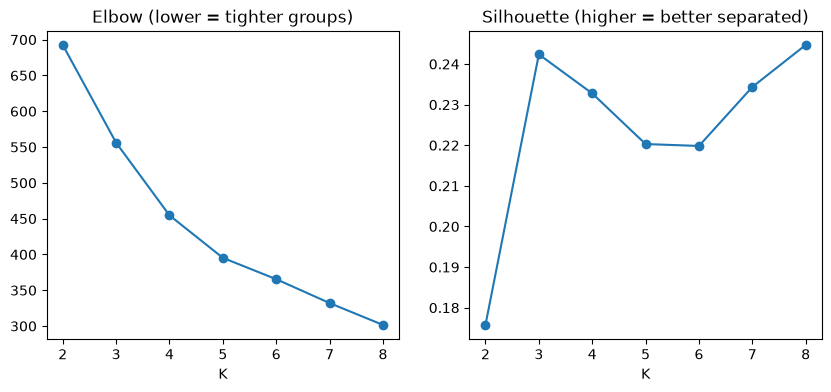

 K  silhouette
 2       0.176
 3       0.242
 4       0.233
 5       0.220
 6       0.220
 7       0.234
 8       0.245


In [3]:
ks = list(range(2, 9))
inertias, sils = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(model.inertia_)
    sils.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow (lower = tighter groups)")
axes[1].plot(ks, sils, marker="o")
axes[1].set_title("Silhouette (higher = better separated)")
for ax in axes:
    ax.set_xlabel("K")
fig.savefig(DOCS / "kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame({"K": ks, "silhouette": np.round(sils, 3)}).to_string(index=False))

In [4]:
K = 4   # <- try 3 if a group is tiny or stability is low
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
agents["cluster"] = km.labels_

print("silhouette:", round(silhouette_score(X, km.labels_), 3))
print(agents["cluster"].value_counts().sort_index().to_string())

silhouette: 0.233
cluster
0    13
1    15
2    23
3    33


In [5]:
aris = []
for seed in range(1, 11):
    other = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X)
    aris.append(adjusted_rand_score(km.labels_, other))
print(f"Stability (ARI vs 10 other seeds): mean {np.mean(aris):.2f}, min {np.min(aris):.2f}")

Stability (ARI vs 10 other seeds): mean 0.62, min 0.50


In [6]:
g = agents.groupby("cluster")
profile = pd.DataFrame({
    "agents": g.size(),
    "bookings": g["bookings"].sum(),
    "cancel_pct": 100 * g["cancellations"].sum() / g["bookings"].sum(),
    "avg_lead_time": g["avg_lead_time"].mean(),
    "avg_adr": g["avg_adr"].mean(),
    "avg_nights": g["avg_nights"].mean(),
    "pct_no_deposit": 100 * g["share_no_deposit"].mean(),
    "pct_online_ta": 100 * g["share_online_ta"].mean(),
    "pct_offline_ta": 100 * g["share_offline_ta"].mean(),
    "pct_groups": 100 * g["share_groups"].mean(),
    "pct_city_hotel": 100 * g["share_city_hotel"].mean(),
}).round(1)
profile["pct_of_agent_bookings"] = (100 * profile["bookings"] / profile["bookings"].sum()).round(1)
print(profile.to_string())
print(f"\nOverall cancel rate for these agents: "
      f"{100 * agents['cancellations'].sum() / agents['bookings'].sum():.1f}%")

         agents  bookings  cancel_pct  avg_lead_time  avg_adr  avg_nights  pct_no_deposit  pct_online_ta  pct_offline_ta  pct_groups  pct_city_hotel  pct_of_agent_bookings
cluster                                                                                                                                                                    
0            13     11701        66.5          167.4     76.9         3.1            57.4            0.0             4.4        94.1            47.6                   12.0
1            15     62943        34.9           75.6    103.8         3.7            97.8           69.8            12.2         4.2            57.3                   64.4
2            23     12244        53.9          153.0    102.2         2.8            56.1            1.1            86.1        12.6            97.8                   12.5
3            33     10827        19.3          106.4     77.3         4.6            96.6            5.9            83.9         8.3        

In [7]:
rows = []
for k in range(2, 7):
    base = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    aris = [adjusted_rand_score(base.labels_,
                                KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X))
            for s in range(1, 11)]
    rows.append({"K": k,
                 "silhouette": round(silhouette_score(X, base.labels_), 3),
                 "stability_mean": round(np.mean(aris), 2),
                 "stability_min": round(np.min(aris), 2),
                 "smallest_group": int(np.bincount(base.labels_).min())})
print(pd.DataFrame(rows).to_string(index=False))

 K  silhouette  stability_mean  stability_min  smallest_group
 2       0.176            0.47          -0.02              31
 3       0.242            0.91           0.26              15
 4       0.233            0.62           0.50              13
 5       0.220            0.83           0.70              14
 6       0.220            0.71           0.56               8


In [8]:
for k in (3, 5):
    base = KMeans(n_clusters=k, n_init=100, random_state=42).fit(X)
    aris = [adjusted_rand_score(base.labels_,
                                KMeans(n_clusters=k, n_init=100, random_state=s).fit_predict(X))
            for s in range(1, 11)]
    sizes = sorted(np.bincount(base.labels_).tolist(), reverse=True)
    print(f"K={k}: silhouette {silhouette_score(X, base.labels_):.3f}, "
          f"stability mean {np.mean(aris):.2f}, worst {np.min(aris):.2f}, group sizes {sizes}")

K=3: silhouette 0.241, stability mean 1.00, worst 1.00, group sizes [51, 17, 16]
K=5: silhouette 0.220, stability mean 0.94, worst 0.91, group sizes [21, 19, 16, 14, 14]


In [9]:
K = 3   # switch to 5 if the big group looks too generic
km = KMeans(n_clusters=K, n_init=100, random_state=42).fit(X)
agents["cluster"] = km.labels_

print("silhouette:", round(silhouette_score(X, km.labels_), 3))
print(agents["cluster"].value_counts().sort_index().to_string())

silhouette: 0.241
cluster
0    51
1    16
2    17


In [10]:
aris = []
for seed in range(1, 11):
    other = KMeans(n_clusters=K, n_init=100, random_state=seed).fit_predict(X)
    aris.append(adjusted_rand_score(km.labels_, other))
print(f"Stability (ARI vs 10 other seeds): mean {np.mean(aris):.2f}, min {np.min(aris):.2f}")

Stability (ARI vs 10 other seeds): mean 1.00, min 1.00


In [11]:
g = agents.groupby("cluster")
profile = pd.DataFrame({
    "agents": g.size(),
    "bookings": g["bookings"].sum(),
    "cancel_pct": 100 * g["cancellations"].sum() / g["bookings"].sum(),
    "avg_lead_time": g["avg_lead_time"].mean(),
    "avg_adr": g["avg_adr"].mean(),
    "avg_nights": g["avg_nights"].mean(),
    "pct_no_deposit": 100 * g["share_no_deposit"].mean(),
    "pct_online_ta": 100 * g["share_online_ta"].mean(),
    "pct_offline_ta": 100 * g["share_offline_ta"].mean(),
    "pct_groups": 100 * g["share_groups"].mean(),
    "pct_city_hotel": 100 * g["share_city_hotel"].mean(),
}).round(1)
profile["pct_of_agent_bookings"] = (100 * profile["bookings"] / profile["bookings"].sum()).round(1)

print(profile.T.to_string())
print(f"\nOverall cancel rate for these agents: "
      f"{100 * agents['cancellations'].sum() / agents['bookings'].sum():.1f}%")

cluster                      0        1        2
agents                    51.0     16.0     17.0
bookings               20959.0  13356.0  63400.0
cancel_pct                36.1     65.9     34.8
avg_lead_time            118.6    185.3     78.1
avg_adr                   87.1     78.8    103.2
avg_nights                 3.8      3.3      3.9
pct_no_deposit            80.9     56.4     97.7
pct_online_ta              2.5      0.0     66.9
pct_offline_ta            87.8     14.1     16.8
pct_groups                 8.3     84.6      4.2
pct_city_hotel            65.2     51.2     51.6
pct_of_agent_bookings     21.4     13.7     64.9

Overall cancel rate for these agents: 39.4%


In [12]:
con = duckdb.connect(str(ROOT / "warehouse.duckdb"), read_only=True)
b = con.execute("""SELECT agent_id, is_canceled, deposit_type
                   FROM mart.bookings_enriched WHERE agent_id IS NOT NULL""").fetchdf()
con.close()
b = b.merge(agents[["agent_id", "cluster"]], on="agent_id")
b["non_refund"] = b["deposit_type"].eq("Non Refund")

summary = pd.DataFrame({
    "pct_non_refund": 100 * b.groupby("cluster")["non_refund"].mean(),
    "cancel_pct_all": 100 * b.groupby("cluster")["is_canceled"].mean(),
    "cancel_pct_excl_non_refund": 100 * b[~b["non_refund"]].groupby("cluster")["is_canceled"].mean(),
}).round(1)
print(summary.to_string())

         pct_non_refund  cancel_pct_all  cancel_pct_excl_non_refund
cluster                                                            
0                  22.5            36.1                        17.5
1                  50.1            65.9                        32.4
2                   0.3            34.8                        34.7


In [13]:
assert agents.groupby("cluster")["share_groups"].mean().idxmax() == 1, "cluster labels changed - re-check NAMES"

NAMES = {0: "Offline travel agents and tour operators",
         1: "Group-booking specialists",
         2: "Online travel agency giants"}
ACTIONS = {
    0: "Standard service. Test resort-stay offers, since only about a third of their bookings are resort.",
    1: "Highest risk (66% cancel rate, 185-day lead). Use staged deposits, rooming-list deadlines, and earlier release of unconfirmed blocks.",
    2: "Protect and optimize. They drive about 57% of cancellations, so small gains matter. Add reconfirmation reminders on long-lead bookings.",
}

agents["segment"] = agents["cluster"].map(NAMES)
agents.drop(columns=["log_bookings"]).to_csv(OUT / "agent_segments.csv", index=False)

seg_table = profile.copy()
seg_table["pct_of_cancellations"] = (100 * agents.groupby("cluster")["cancellations"].sum()
                                     / agents["cancellations"].sum()).round(1)
seg_table["segment"] = seg_table.index.map(NAMES)
seg_table["recommended_action"] = seg_table.index.map(ACTIONS)
seg_table.to_csv(OUT / "segment_profile.csv")
print(seg_table[["segment", "agents", "pct_of_agent_bookings", "pct_of_cancellations", "cancel_pct"]].to_string())

                                          segment  agents  pct_of_agent_bookings  pct_of_cancellations  cancel_pct
cluster                                                                                                           
0        Offline travel agents and tour operators      51                   21.4                  19.7        36.1
1                       Group-booking specialists      16                   13.7                  22.9        65.9
2                     Online travel agency giants      17                   64.9                  57.4        34.8


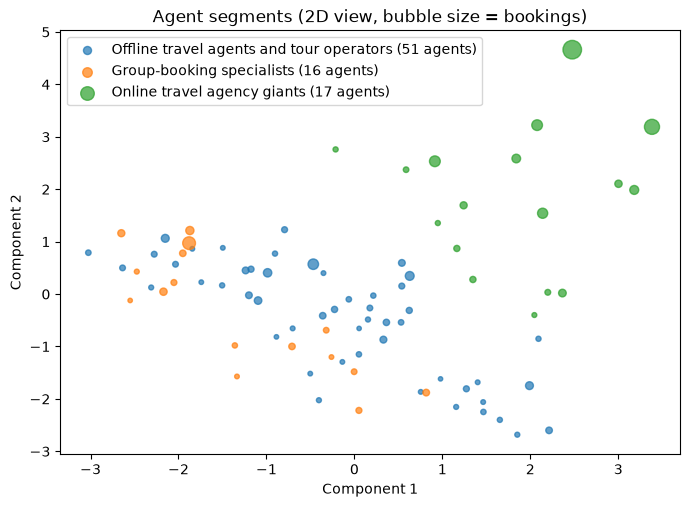

In [14]:
pcs = PCA(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 5.5))
for c, name in NAMES.items():
    m = (agents["cluster"] == c).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=np.sqrt(agents.loc[m, "bookings"]),
               alpha=0.7, label=f"{name} ({m.sum()} agents)")
ax.legend()
ax.set_title("Agent segments (2D view, bubble size = bookings)")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
fig.savefig(DOCS / "agent_segments_pca.png", dpi=150, bbox_inches="tight")
plt.show()


In [15]:
assert agents.groupby("cluster")["share_groups"].mean().idxmax() == 1, "cluster labels changed - re-check NAMES"

NAMES = {0: "Offline travel agents and tour operators",
         1: "Group-booking specialists",
         2: "Online travel agency giants"}
ACTIONS = {
    0: "Lowest underlying cancel rate (17.5% excluding Non Refund). Protect the relationship and test resort-stay offers, since only about a third of their bookings are resort.",
    1: "Half their bookings are Non Refund, recorded as about 99% cancelled. Excluding those, cancellation is 32%. Investigate how Non Refund bookings are recorded before acting, and use rooming-list deadlines to manage their 185-day lead times.",
    2: "Biggest source of cancellations (about 57% of the total, and more once Non Refund is set aside). Small improvements matter most here, so add reconfirmation reminders on long-lead bookings.",
}

agents["segment"] = agents["cluster"].map(NAMES)
agents.drop(columns=["log_bookings"]).to_csv(OUT / "agent_segments.csv", index=False)

seg_table = profile.copy()
seg_table["pct_of_cancellations"] = (100 * agents.groupby("cluster")["cancellations"].sum()
                                     / agents["cancellations"].sum()).round(1)
seg_table = seg_table.join(summary[["pct_non_refund", "cancel_pct_excl_non_refund"]])
seg_table["segment"] = seg_table.index.map(NAMES)
seg_table["recommended_action"] = seg_table.index.map(ACTIONS)
seg_table.to_csv(OUT / "segment_profile.csv")
print(seg_table[["segment", "agents", "pct_of_cancellations", "cancel_pct",
                 "cancel_pct_excl_non_refund"]].to_string())

                                          segment  agents  pct_of_cancellations  cancel_pct  cancel_pct_excl_non_refund
cluster                                                                                                                
0        Offline travel agents and tour operators      51                  19.7        36.1                        17.5
1                       Group-booking specialists      16                  22.9        65.9                        32.4
2                     Online travel agency giants      17                  57.4        34.8                        34.7
